# EDA полного датасета Авито

Полный проход по train / val / test: все шарды, ленты, кандидаты и события
истории. Выборка не использовалась. Статистики считаются до обучения моделей;
качество модели здесь не измеряется. Время показано в UTC.

Подготовка: `python -m scripts.prepare_data --data competition --out data/prepared --eda-out runs/eda`.
Перестроение отчёта: `python -m scripts.build_eda_notebook`.
Рядом с ноутбуком лежит снимок агрегатов `eda_summary.json` для просмотра без сырых данных.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
source = ROOT / "runs/eda/summary.json"
if not source.exists():
    source = ROOT / "notebooks/eda_summary.json"
eda = json.loads(source.read_text(encoding="utf-8"))
assert eda["complete"]
splits = eda["splits"]
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": .2})
print("Scope:", eda["scope"])
print("Template keys:", eda["test_template_key_coverage"])
print("Missing IDs:", eda["missing_id_policy"])


Scope: all shards, all feeds and all candidate/history list values; no sampling
Template keys: exact_match
Missing IDs: ID 0 excluded from distinct counts and overlaps; occurrences reported separately


## Объём, целевые действия и даты

CTR — доля позитивных кандидатов, а не доля лент. Долю лент без позитивов
показываем отдельно: по эталону такая лента получает NDCG=1. У test нет
опубликованных меток, поэтому соответствующие показатели отсутствуют.


In [2]:
rows = []
for name, s in splits.items():
    rows.append({"split": name, "feeds": s["feeds"], "candidates": s["candidates"],
                 "positives": s["positives"], "CTR": s["ctr"],
                 "feeds_without_positives_%": 100 * s["feeds_without_positives"] / s["feeds"] if s["positives"] is not None else None,
                 "unique_users": s["unique_users"], "unique_candidate_items": s["unique_candidate_items"],
                 "start_UTC": s["dates_utc"]["min"], "end_UTC": s["dates_utc"]["max"]})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.6f}"))


split   feeds  candidates      positives      CTR  feeds_without_positives_%  unique_users  unique_candidate_items                 start_UTC                   end_UTC
train 3151208   246745836 5446872.000000 0.022075                   0.000000       2455381                38950205 2026-09-05T21:00:48+00:00 2026-09-19T21:00:48+00:00
  val   14423     1389971   21983.000000 0.015815                   0.000000         13740                 1239391 2026-09-21T21:00:48+00:00 2026-09-24T21:00:48+00:00
 test   28595     2904806            NaN      NaN                        NaN         27308                 2381673 2026-09-25T21:00:48+00:00 2026-09-29T20:58:40+00:00


## Размеры лент и историй

Квантили точные: восстановлены из полного гистограммного счётчика с линейной
интерполяцией, как `numpy.quantile`. На графике числа лент показаны в долях;
логарифмическая ось Y помогает увидеть редкие размеры.


split distribution   count  min  max   mean   p10    p50    p90    p99
train    feed_size 3151208    5  300  78.30  9.00  48.00 213.00 281.00
train history_size 3151208    0  256 185.19 48.00 225.00 256.00 256.00
  val    feed_size   14423    5  299  96.37 12.00  67.00 247.00 291.00
  val history_size   14423    0  256 173.30 46.00 191.00 256.00 256.00
 test    feed_size   28595    5  300 101.58 13.00  72.00 256.00 292.00
 test history_size   28595    0  256 173.92 49.00 189.00 256.00 256.00


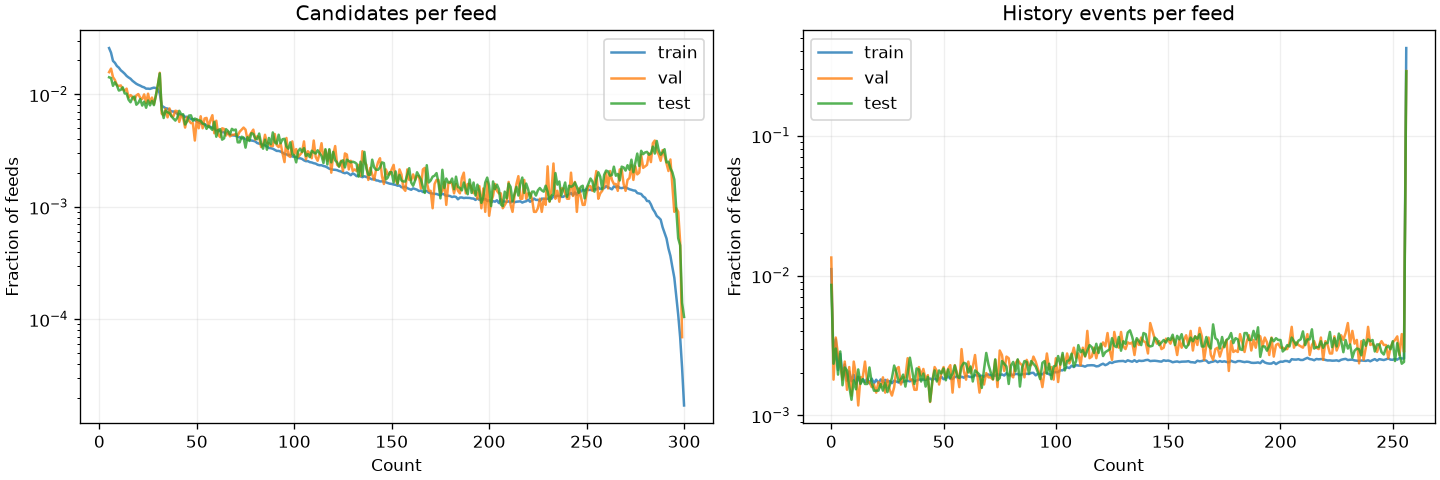

In [3]:
rows = []
for name, s in splits.items():
    for field in ("feed_size", "history_size"):
        rows.append({"split": name, "distribution": field,
                     **{k: v for k, v in s[field].items() if k != "histogram"}})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.2f}"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, field, title in zip(axes, ["feed_size", "history_size"], ["Candidates per feed", "History events per feed"]):
    for name, s in splits.items():
        hist = s[field]["histogram"]
        x = sorted(map(int, hist))
        y = [hist[str(i)] / s["feeds"] for i in x]
        ax.plot(x, y, label=name, alpha=.8)
    ax.set(title=title, xlabel="Count", ylabel="Fraction of feeds", yscale="log")
    ax.legend()
plt.show()


## CTR по исходной позиции в train

В train сохранена продовая позиция; val/test получены со случайным показом.
График описывает наблюдаемую зависимость, в которой одновременно участвуют
порядок показа и качество кандидатов. Сам по себе он не оценивает propensity
и не задаёт готовые IPW-веса. Нумерация с 0, после фильтрации есть пропуски.


 position  impressions  positives      ctr
        0      2686066     317347 0.118146
        1      2717503     208072 0.076567
        2      2740544     181831 0.066349
        3      2755250     177557 0.064443
        4      2759717     147158 0.053324
        5      2719510     138233 0.050830
        6      2663820     126288 0.047409
        7      2617872     120761 0.046129
        8      2571659     111610 0.043400
        9      2530973     106572 0.042107
       10      2486901     100823 0.040542
       11      2447335      94621 0.038663
       12      2407661      89108 0.037010
       13      2369363      86361 0.036449
       14      2334133      82686 0.035425
       15      2300673      78416 0.034084
       16      2265579      74145 0.032727
       17      2232197      71446 0.032007
       18      2201337      68663 0.031191
       19      2171268      66329 0.030549


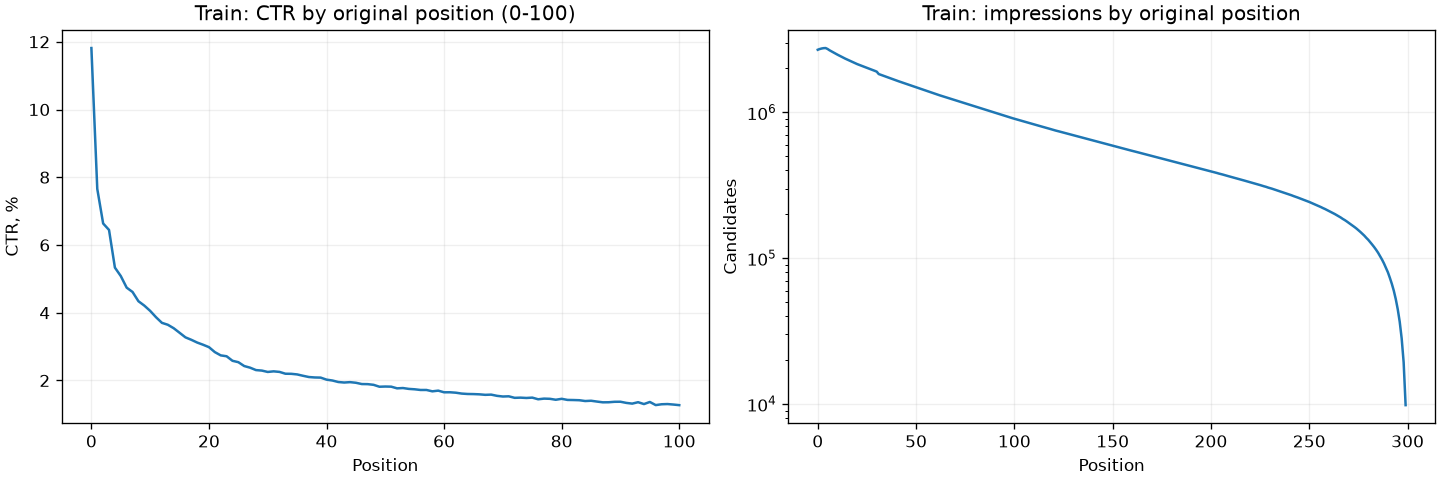

In [4]:
position = pd.DataFrame([{"position": int(k), **v} for k, v in splits["train"]["ctr_by_position"].items()]).sort_values("position")
print(position.head(20).to_string(index=False, float_format=lambda x: f"{x:.6f}"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
shown = position[position.position <= 100]
axes[0].plot(shown.position, 100 * shown.ctr)
axes[0].set(title="Train: CTR by original position (0-100)", xlabel="Position", ylabel="CTR, %")
axes[1].plot(position.position, position.impressions)
axes[1].set(title="Train: impressions by original position", xlabel="Position", ylabel="Candidates", yscale="log")
plt.show()


## Пропуски эмбеддингов и отсутствующие ID

`-1` — отсутствие эмбеддинга: его нельзя использовать как индекс массива.
Нулевые user/item ID считаются отсутствующими и исключены из числа уникальных
объектов и пересечений. Количество таких вхождений приведено отдельно.


In [5]:
rows = []
for name, s in splits.items():
    rows.append({"split": name,
                 "candidate_missing": s["candidate_missing_embeddings"],
                 "candidate_missing_%": 100 * s["candidate_missing_embedding_rate"],
                 "history_missing": s["history_missing_embeddings"],
                 "history_missing_%": 100 * s["history_missing_embedding_rate"],
                 **{f"zero_{key}_ids": value for key, value in s["zero_ids"].items()}})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.4f}"))


split  candidate_missing  candidate_missing_%  history_missing  history_missing_%  zero_users_ids  zero_candidates_ids  zero_history_ids
train               7924               0.0032         90521519            15.5112          123904                    0                 0
  val                214               0.0154           355067            14.2053             658                    0                 0
 test                455               0.0157           698183            14.0392            1179                    0                 0


## Повторные товары внутри ленты

Некоторые item_id повторяются в одной train-ленте с различными позициями
и признаками. Все исходные вхождения сохранены; метки не агрегировались.
Поэтому уникальный ключ строки — `(split, feed_id, candidate_index)`.
`candidate_index` — технический номер в исходном списке, его не следует
включать в модельные признаки. Группы item-признаков соединяют по
`(split, feed_id, item_id)` как many-to-one; признаки конкретного
вхождения — по ключу с candidate_index. Подробные повторные строки
сохранены локально в `runs/eda/duplicate_candidates/`.


In [6]:
rows = [{"split": name, **{field: s[field] for field in
         ("duplicate_item_pairs", "duplicate_item_feeds", "duplicate_item_rows_excess", "conflicting_target_pairs")}}
        for name, s in splits.items()]
print(pd.DataFrame(rows).to_string(index=False))


split  duplicate_item_pairs  duplicate_item_feeds  duplicate_item_rows_excess  conflicting_target_pairs
train                     4                     1                           4                         0
  val                     0                     0                           0                         0
 test                     0                     0                           0                         0


## Пересечения пользователей и товаров

Точные пересечения уникальных ID, без выборки и приближённых оценок.
Кандидаты и товары из истории показаны отдельно. `fraction_of_right` отвечает,
какая доля уникальных ID правого split уже была в левом. Это доля уникальных
объектов, а не доля строк или показов.


In [7]:
overlap = pd.DataFrame(eda["overlaps"])
print(overlap.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


 left right          entity  intersection  left_unique  right_unique  fraction_of_left  fraction_of_right
train   val           users          4369      2455381         13740            0.0018             0.3180
train   val candidate_items        805458     38950205       1239391            0.0207             0.6499
train   val   history_items       1332626     94705754       1584249            0.0141             0.8412
train  test           users          8262      2455381         27308            0.0034             0.3025
train  test candidate_items       1273893     38950205       2381673            0.0327             0.5349
train  test   history_items       2378370     94705754       3010579            0.0251             0.7900
  val  test           users            92        13740         27308            0.0067             0.0034
  val  test candidate_items        219526      1239391       2381673            0.1771             0.0922
  val  test   history_items        227658     

## Даты и изменение распределения признаков

Между периодами есть временные зазоры. Сводки f1–f5 вычислены по всем
кандидатам; стандартное отклонение — генеральное (`ddof=0`).


split   date_UTC  feeds  candidates  positives
train 2026-09-05  14924     1317217    28573.0
train 2026-09-06 291720    23764997   514062.0
train 2026-09-07 278685    21979889   477262.0
train 2026-09-08 292777    23095052   503558.0
train 2026-09-09 285929    21945283   487487.0
train 2026-09-10 283125    21458256   483137.0
train 2026-09-11 247575    19202494   426593.0
train 2026-09-12 204189    16090440   355827.0
train 2026-09-13 263061    20998641   455655.0
train 2026-09-14 230459    17761100   389818.0
train 2026-09-16  13327     1147190    25464.0
train 2026-09-17 269288    20684955   464546.0
train 2026-09-18 257312    20020756   449050.0
train 2026-09-19 218837    17279566   385840.0
  val 2026-09-21    354       36821      563.0
  val 2026-09-22   7189      690940    10934.0
  val 2026-09-23    392       42399      661.0
  val 2026-09-24   6488      619811     9825.0
 test 2026-09-25    363       40532        NaN
 test 2026-09-26   6124      631686        NaN
 test 2026-09

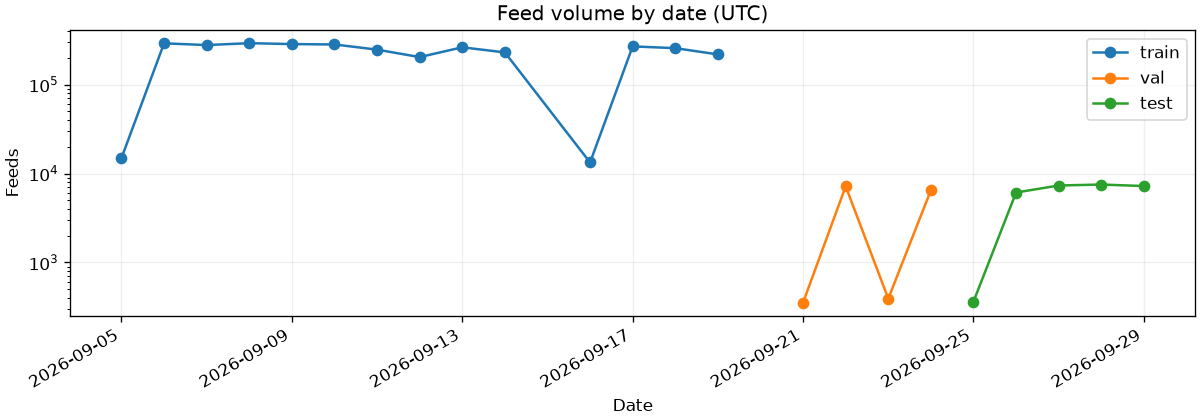

In [8]:
rows = []
for name, s in splits.items():
    for day, values in s["by_day_utc"].items():
        rows.append({"split": name, "date_UTC": day, **values})
daily = pd.DataFrame(rows)
print(daily.to_string(index=False))
features = pd.DataFrame([{"split": name, "feature": feature, **values}
                         for name, s in splits.items() for feature, values in s["features"].items()])
print("\nFeature distributions:")
print(features.to_string(index=False, float_format=lambda x: f"{x:.5f}"))
fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
for name in splits:
    part = daily[daily.split == name]
    ax.plot(pd.to_datetime(part.date_UTC), part.feeds, marker="o", label=name)
ax.set(title="Feed volume by date (UTC)", xlabel="Date", ylabel="Feeds", yscale="log")
ax.legend()
fig.autofmt_xdate()
plt.show()


## Категории и типы событий

Коды событий категориальные; по одному номеру нельзя приписывать им
бизнес-смысл. Частоты считаются по всем вхождениям событий в опубликованные
истории: одна и та же активность может повторяться в историях разных лент.



history_event_types (event occurrences):
        train      val     test
1   302792976  1096543  2192883
2    67901385   348525   684997
3    63156885   300741   596574
4    54223978   267900   531547
5    25707726   132438   263893
6    24009008   116642   233890
7    21409468   106080   211789
8    14890109    80126   157689
9     6936534    37434    75436
10    2558309    13118    24408

history_event_sources (event occurrences):
        train      val     test
0   229599645  1135724  2246672
1   219251107   843848  1707277
2    92979765   344509   672810
3    12995105    64634   126343
4    11184133    44530    88655
5     5799314    23124    44526
6     4609383    16373    34581
7     4385964    16840    32958
8      870108     2529     5149
9      544216     2256     4153
10     480831     1660     3094
11     364222     1315     2810
12     256022      960     1729
13     110596      584     1017
14      34536      140      315
15      33996      109      269
16      27506     

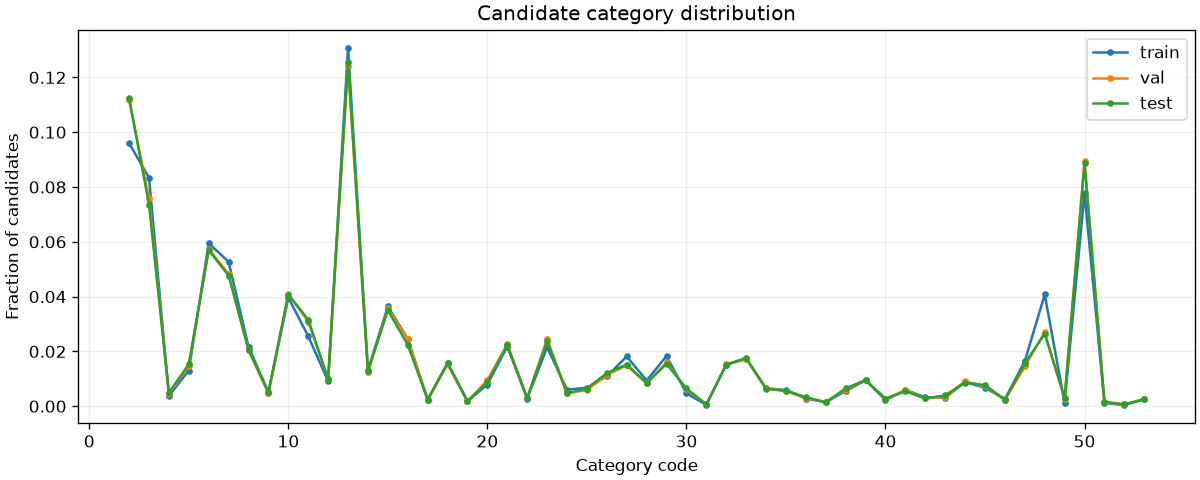

In [9]:
for field in ("history_event_types", "history_event_sources"):
    table = pd.DataFrame({name: pd.Series({int(k): v for k, v in s[field].items()}) for name, s in splits.items()}).fillna(0).astype("int64").sort_index()
    print("\n" + field + " (event occurrences):")
    print(table.to_string())
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for name, s in splits.items():
    hist = {int(k): v / s["candidates"] for k, v in s["candidate_categories"].items()}
    keys = sorted(hist)
    ax.plot(keys, [hist[k] for k in keys], marker=".", label=name)
ax.set(title="Candidate category distribution", xlabel="Category code", ylabel="Fraction of candidates")
ax.legend()
plt.show()


## Табличные данные для команды

`data/prepared/<split>/candidates/*.parquet`: одна строка на кандидата;
ключ `(split, feed_id, candidate_index)`, item_id, f1–f5, категория, индекс эмбеддинга,
user_id, timestamp; target только для train/val, pos только для train.

`data/prepared/<split>/feeds/*.parquet`: одна строка на ленту; история,
user_embedding, timestamp, user_id, feed_size. Связь по `(split, feed_id)`.
Истории не размножены на каждого кандидата. Индексы эмбеддингов относятся
к таблице **своего split** в `competition/<split>/item_embeddings/`.

Готовность и перечень частей: `data/prepared/manifest.json`.
Набор принимается только при `complete=true`. При прерывании запускать
подготовку с `--resume`: неизменённые части повторно не записываются,
агрегаты EDA пересчитываются полностью.

Для ленивого чтения:
```python
from src.common.preparation import scan_candidates
val = scan_candidates("data/prepared", "val")
# val.select("feed_id", "item_id", "f1", "target").collect()
```

Это базовые таблицы с исходными признаками. Косинусы к истории, OOF-статистики
и обученные признаки добавляются отдельными группами по ключам.
Признаки из будущих историй здесь не строились.


## Выводы для следующих экспериментов

- В train **246,745,836** кандидатов, в val **1,389,971**,
  в test **2,904,806**. Обучение на всём train требует чтения
  по частям или отдельного планирования памяти; для быстрых экспериментов
  выбирать целые ленты.
- Доля позитивов: train **2.2075%**, val **1.5815%**.
  Train и val собраны разными способами, поэтому одного совпадения
  распределения признаков недостаточно: модель нужно сравнивать на val.
- **0.00%** лент val не имеют
  позитивов и получают NDCG=1 при любом ранжировании. Вместе с общей метрикой
  полезно смотреть качество на лентах с позитивами, сохраняя эталонную
  общую метрику для сравнения решений.
- **31.80%** уникальных пользователей val встречались в train;
  **64.99%** уникальных товаров-кандидатов val
  встречались среди кандидатов train. Стоит отдельно оценивать метрику
  для знакомых и новых ID. Эти проценты относятся к уникальным ID,
  а не к доле показов.
- Отсутствующие эмбеддинги кандидатов: train
  **0.0032%**, val
  **0.0154%**, test
  **0.0157%**. Обработку `-1`
  и признак наличия эмбеддинга сохранять в обоих модельных пайплайнах.
- Зависимость CTR от позиции показана выше; сравнить способы дебайаса
  по псевдо-Private. Исторические таргетные статистики считать по прошлому
  или OOF. Смысл event_type исследовать отдельно: по частотам кодов он
  не определяется.
